# CLASE COSMOLOGÍA - ACTIVIDAD PRÁCTICA

¡Bienvenidos a su primer trabajo como Astronomos!

En esta experiencia serás parte del equipo que intentará estimar la **constante de Hubble** ($H_0$), que es el valor que utilizamos para saber a qué ritmo se expande el universo.

Como vimos en la clase teórica existen 3 formas de medir esta constante, en este notebook, tú y tu equipo lo medirán utilizando el método del **Fondo Cósmico de Microondas**


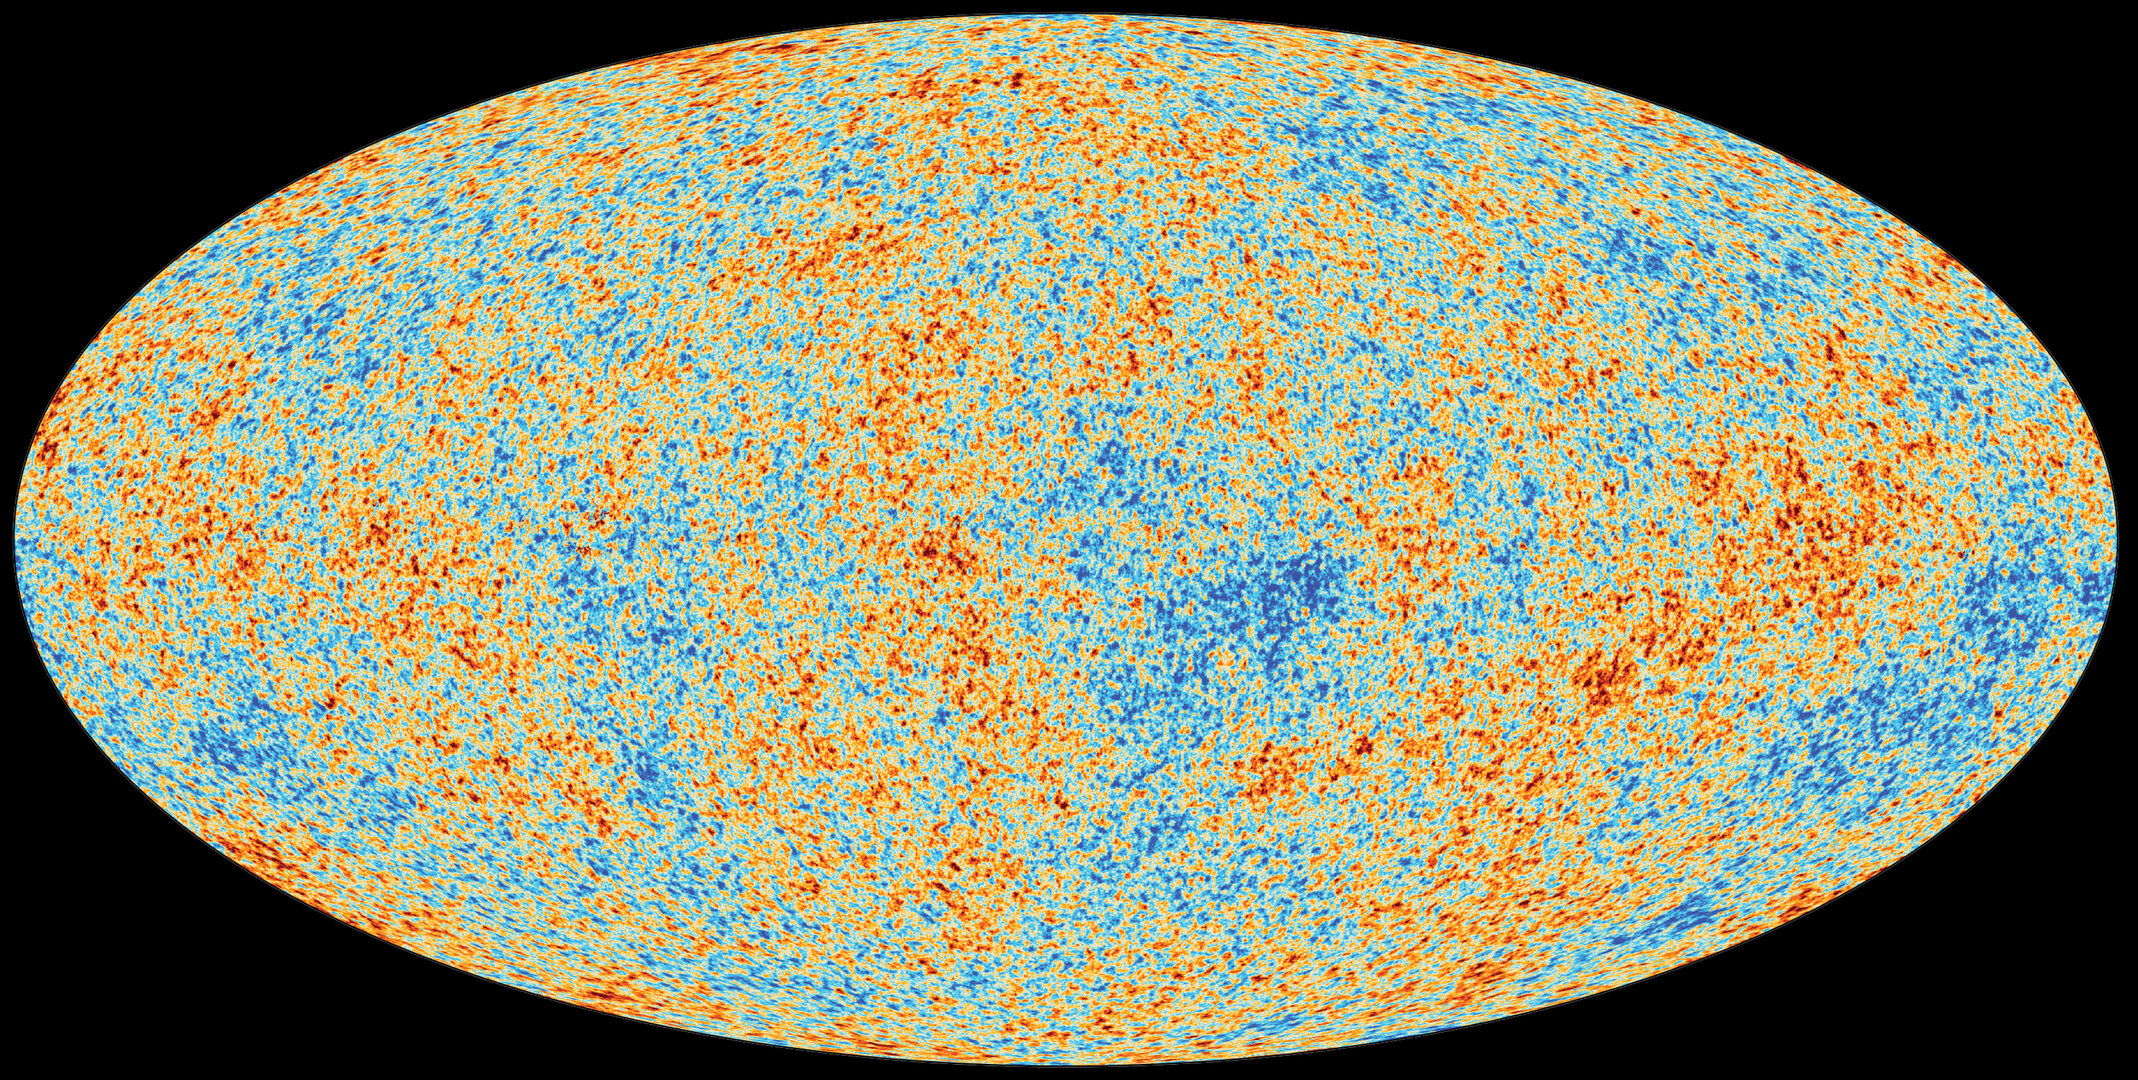

Fuente de imagen: ESA

Como recordatorio: El Fondo Cósmico de Microondas (CMB por sus siglas en inglés) es lo que llamamos la luz más antiguas del unvierso, cuando el universo todavía se estaba formando. Los colores que ves, son pequeñísimas variaciones de temperaturas.

# Astrónomo observacional

Tu rol aquí es interpretar los datos que te entrega el operador de telescopio, lo que tienes abajo son los códigos necesarios para poner a prueba y estimar la constante de Hubble.

In [1]:
## Carga de bibliotecas ##
# No borres nada de esto #
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, widgets

print("📡 ¡Telescopio listo para recibir datos del CMB!")

📡 ¡Telescopio listo para recibir datos del CMB!


Los astrónomos teóricos tienen una idea de cómo debe verse la gráfica de la expansión del universo, pero claro, necesitamos los datos observacionales para determinar $H_0$ y así confirmar su valor. Puedes echarle un vistazo a lo que ellos dicen:

In [2]:
# <-- Presiona el botón de play

def modelo_teorico_cmb(x_escalas, H0):
    # El factor de escala desplaza el gráfico según el valor de H0 introducido
    desplazamiento = (H0 - 67) * 1.5
    x_ajustado = x_escalas - desplazamiento

    # Fórmula matemática para crear tres "picos" u ondas de temperatura decrecientes
    peak1 = 5000 * np.exp(-((x_ajustado - 220)/120)**2)
    peak2 = 2500 * np.exp(-((x_ajustado - 540)/100)**2)
    peak3 = 1500 * np.exp(-((x_ajustado - 800)/80)**2)
    fondo_decreciente = 800 * np.exp(-x_ajustado/400)

    return peak1 + peak2 + peak3 + fondo_decreciente


# Esta función pone los ejes con sus unidades en todos los gráficos del CMB
def formato_ejes_cmb(ax):
    ax.set_xlabel("Escala angular: multipolo ℓ   (← manchas grandes  |  manchas pequeñas →)", fontsize=11)
    ax.set_ylabel("Fluctuación de temperatura [μK²]", fontsize=11)
    # Eje superior: tamaño aproximado de la mancha en el cielo (θ ≈ 180° / ℓ)
    a_grados = lambda l: 180 / np.maximum(l, 1e-6)
    eje_sup = ax.secondary_xaxis('top', functions=(a_grados, a_grados))
    eje_sup.set_xticks([1, 0.5, 0.3, 0.2, 0.15])
    eje_sup.set_xticklabels(["1°", "0,5°", "0,3°", "0,2°", "0,15°"])
    eje_sup.set_xlabel("Tamaño aproximado de la mancha en el cielo [grados]", fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)


# Esta función lo que hace es generar la gráfica teórica.
def ajustar_modelo(H0):
    # Genera una curva teórica basada en el H0 seleccionado
    x_teorico = np.linspace(100, 1500, 200)
    y_teorico = modelo_teorico_cmb(x_teorico, H0)

    fig, ax = plt.subplots(figsize=(9, 4.5))

    # Dibujamos la línea teórica
    linea = ax.plot(x_teorico, y_teorico, color='black', linewidth=1, zorder=1)

    # Añadimos un degradado de fondo que asocie el eje Y con los colores del mapa del CMB
    # Azul = Frío/Neutro, Rojo = Caliente/Extremo
    sc = ax.scatter(x_teorico, y_teorico, c=y_teorico, cmap='RdYlBu_r', s=40, edgecolor='none', zorder=2)

    # Creamos la barra de colores lateral para que los estudiantes asocien intensidad con color
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('Fluctuación [μK²]  (Azul = suave | Rojo = intensa)', rotation=270, labelpad=15)

    ax.set_title("Ajusta el valor de la expansión del Universo")
    formato_ejes_cmb(ax)
    plt.show()

print("✅ ¡Modelos teóricos listos con barra de colores!")

✅ ¡Modelos teóricos listos con barra de colores!


In [3]:
# <--- Aprieta play para iniciar la simulación
def ajustar_modelo(H0):
    # Genera una curva teórica basada en el H0 seleccionado
    x_teorico = np.linspace(100, 1500, 200)
    y_teorico = modelo_teorico_cmb(x_teorico, H0)

    fig, ax = plt.subplots(figsize=(9, 4.5))

    # Graficar el modelo con colores según la intensidad (representando el mapa del CMB)
    sc = ax.scatter(x_teorico, y_teorico, c=y_teorico, cmap='RdYlBu_r', s=25, zorder=2)
    ax.plot(x_teorico, y_teorico, color='gray', alpha=0.5, zorder=1, label=f'Modelo Teórico ($H_0$ = {H0})')

    # Barra de colores para guiar visualmente
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('Fluctuación [μK²]  (Azul = suave | Rojo = intensa)', rotation=270, labelpad=15)

    ax.set_title("Ajusta el valor de la expansión del Universo")
    formato_ejes_cmb(ax)
    ax.set_xlim(100, 1500)
    ax.set_ylim(0, 7000)
    ax.legend(loc='upper right')
    plt.show()

# Crear deslizador entre 20 y 150 km/s/Mpc
interact(ajustar_modelo, H0=widgets.IntSlider(min=20, max=150, step=1, value=50, description='Velocidad H0:'));

interactive(children=(IntSlider(value=50, description='Velocidad H0:', max=150, min=20), Output()), _dom_class…

Fíjate que, a medida que mueves el deslizador, la curva también lo hace.

### 🗺️ ¿Cómo se conecta este gráfico con el mapa de manchas de colores del satélite Planck?

¡Es una relación directa! Puedes entender los ejes de la siguiente manera:

* **El eje X (Escala Angular, llamada *multipolo ℓ*) representa el TAMAÑO de las manchas:**
  * Hacia la **izquierda** (valores pequeños) medimos las manchas más **grandes** del mapa.
  * Hacia la **derecha** (valores grandes) medimos las manchas más **pequeñas y finas**.
  * El eje de **arriba** traduce ℓ a grados en el cielo (≈ 180° / ℓ). El primer pico, en ℓ ≈ 220, son manchas de casi **1°**: ¡el doble del tamaño de la Luna llena!

* **El eje Y (Fluctuación de temperatura, en μK²) representa el COLOR de las manchas:**
  * Las zonas más **altas** del gráfico (alta intensidad) representan las variaciones de temperatura más fuertes en el mapa. En la famosa foto del telescopio Planck, estas corresponden a los puntos de color **rojo/naranja** (más calientes) y **azul oscuro** (más fríos).
  * Las zonas más **bajas** corresponden a las áreas donde la temperatura es más neutra o promedio.

# Pasar los datos

El operador del telescopio espacial Planck, después de arduas horas de monitoreo ha obtenido los resultados que necesitas para modelar el valor de $H_0$. Para eso, pídele que te dicte estos valores para insertarlos abajo

In [4]:
# @title 📥 Ingreso de Datos del Telescopio (¡Trabajo en Parejas!)
import ipywidgets as widgets
from IPython.display import display, HTML

# Explicación para los estudiantes
display(HTML("<h3>📡 Panel de Recepción de Datos</h3>"))
display(HTML("<p>Pídele a tu compañero/a operador los datos de su tabla e ingrésalos aquí:</p>"))

# Creamos los campos interactivos de entrada
entradas_x = []
entradas_y = []

for i in range(1, 16):
    # Usamos widgets.HTML en lugar del HTML tradicional de IPython para que sea compatible con HBox
    html_label = widgets.HTML(value=f"<b>Punto {i}:</b> ", layout=widgets.Layout(width='80px'))
    input_x = widgets.IntText(value=0, description='Escala X:', style={'description_width': 'initial'}, layout=widgets.Layout(width='180px'))
    input_y = widgets.IntText(value=0, description='Intensidad Y:', style={'description_width': 'initial'}, layout=widgets.Layout(width='180px'))

    # Agrupamos visualmente en una fila
    fila = widgets.HBox([html_label, input_x, input_y])
    display(fila)

    entradas_x.append(input_x)
    entradas_y.append(input_y)

# Botón para registrar los datos en el sistema
boton_guardar = widgets.Button(
    description='💾 Registrar Datos',
    button_style='success',
    tooltip='Haz clic para cargar estos datos en el gráfico',
    icon='check'
)

salida_mensaje = widgets.Output()

def procesar_datos(b):
    global escalas_angulares, temperatura
    with salida_mensaje:
        salida_mensaje.clear_output()
        # Extraemos los valores de los widgets
        valores_x = [w.value for w in entradas_x]
        valores_y = [w.value for w in entradas_y]

        # Guardamos en las variables globales que usará el gráfico
        import numpy as np
        escalas_angulares = np.array(valores_x)
        temperatura = np.array(valores_y)

        print("\n✅ ¡Datos guardados con éxito en la memoria del telescopio!")
        print(f"Datos ingresados:\nEje X (Escala): {valores_x}\nEje Y (Intensidad): {valores_y}")
        print("👉 ¡Ya puedes avanzar a la siguiente celda para graficarlos!")

boton_guardar.on_click(procesar_datos)

# Creamos espacio vertical usando un Box con Layout en lugar de Spacer
espaciador = widgets.Box(layout=widgets.Layout(height='10px'))
display(espaciador)

display(boton_guardar)
display(salida_mensaje)

Box(layout=Layout(height='10px'))

Button(button_style='success', description='💾 Registrar Datos', icon='check', style=ButtonStyle(), tooltip='Ha…

Output()

### 📊 ¡Ajusta tu modelo teórico con tus datos!
Ejecuta la siguiente celda para abrir el simulador. Mueve el deslizador para cambiar el valor de la Constante de Hubble ($H_0$) y observa cómo la curva teórica intenta calzar con los puntos naranjas que ingresaste con tu compañero/a.

In [5]:
# @title 🎛️ Simulador: Ajuste de Datos Observacionales vs Modelo Teórico

def graficar_comparacion(H0):
    global escalas_angulares, temperatura

    # Generamos la curva teórica según el H0 seleccionado
    x_teorico = np.linspace(100, 1200, 300)
    y_teorico = modelo_teorico_cmb(x_teorico, H0)

    fig, ax = plt.subplots(figsize=(10, 5))

    # 1. Graficamos la curva teórica con scatter de color para representar la temperatura CMB
    sc = ax.scatter(x_teorico, y_teorico, c=y_teorico, cmap='RdYlBu_r', s=15, zorder=1)
    ax.plot(x_teorico, y_teorico, color='gray', alpha=0.5, zorder=1, label=f'Modelo Teórico ($H_0$ = {H0})')

    # 2. Graficamos los datos observacionales que ingresaron los estudiantes
    # Verificamos primero si ya se han ingresado datos válidos (distintos de cero)
    if 'escalas_angulares' in globals() and len(escalas_angulares) > 0 and not np.all(escalas_angulares == 0):
        ax.scatter(escalas_angulares, temperatura, color='darkorange', edgecolor='black', s=100, label='Tus Datos Registrados', zorder=3)

        # Anotamos los puntos para que los estudiantes los identifiquen fácilmente
        for i, (xi, yi) in enumerate(zip(escalas_angulares, temperatura)):
            ax.annotate(f"P{i+1}", (xi, yi), textcoords="offset points", xytext=(0,10), ha='center', fontweight='bold', color='darkgreen')
    else:
        # Mensaje de advertencia si aún no han ingresado datos
        ax.text(0.5, 0.5, '⚠️ Ingresa y registra tus datos en la celda de arriba\npara verlos aquí.',
                horizontalalignment='center', verticalalignment='center', transform=ax.transAxes,
                fontsize=12, color='red', bbox=dict(facecolor='white', alpha=0.8))

    # Formato y estilo amigable para los alumnos
    cbar = fig.colorbar(sc, ax=ax)
    cbar.set_label('Fluctuación [μK²]  (Azul = suave | Rojo = intensa)', rotation=270, labelpad=15)

    ax.set_title(" Buscando la Expansión del Universo $(H_0)$", fontsize=14, fontweight='bold')
    formato_ejes_cmb(ax)
    ax.set_xlim(100, 1200)
    ax.set_ylim(0, 7000)
    ax.legend(loc='upper right', fontsize=10)
    plt.show()

# Crear el control deslizante interactivo
interact(graficar_comparacion, H0=widgets.IntSlider(min=40, max=100, step=1, value=40, description='Velocidad H0:'));

interactive(children=(IntSlider(value=40, description='Velocidad H0:', min=40), Output()), _dom_classes=('widg…

#¿Cuál es el valor de la constante?

Después de interactuar con el gráfico:


*  ¿A qué valor se expande el universo?
*  ¿Qué tan preciso crees que es este valor?


